In [1]:
import boto3
import sagemaker
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

sns.set_theme()

sess = sagemaker.Session()
bucket = sess.default_bucket()
role = sagemaker.get_execution_role()
region = boto3.Session().region_name

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


In [2]:
%store -r
%store

Stored variables and their in-db values:
bucket                                   -> 'sagemaker-us-east-1-298748835671'
ingestion_completed                      -> True
project_prefix                           -> 'cat-landmarks-project'
s3_processed_cats_prefix                 -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_processed_combined_prefix             -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_raw_cats_prefix                       -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_raw_noncats_prefix                    -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
setup_dependencies_passed                -> True
setup_s3_bucket_passed                   -> True


In [3]:
ingest_create_athena_db_passed = False

In [4]:
# Restore project S3 paths created during ingestion
project_prefix = project_prefix
s3_raw_cats_prefix = s3_raw_cats_prefix
s3_raw_noncats_prefix = s3_raw_noncats_prefix
s3_processed_combined_prefix = s3_processed_combined_prefix
s3_processed_cats_prefix = s3_processed_cats_prefix

print("Cats:", s3_raw_cats_prefix)
print("Noncats:", s3_raw_noncats_prefix)
print("Processed/combined:", s3_processed_combined_prefix)
print("Processed/cats:", s3_processed_cats_prefix)

Cats: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/raw/cats/
Noncats: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/raw/noncats/noncat_images/
Processed/combined: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/processed/combined/
Processed/cats: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/processed/cats/


# Setting up Athena

In [5]:
database_name = "cat_landmarking"
manifest_table = "image_manifest"
landmarks_table = "cat_annotations"

s3_staging_dir = f"s3://{bucket}/{project_prefix}/athena/staging/"

engine = create_engine(
    f"awsathena+rest://@athena.{region}.amazonaws.com:443/"
    f"{database_name}"
    f"?s3_staging_dir={s3_staging_dir}"
)

In [ ]:
# Clean up this project's database from previous runs.
# Scoped to database_name only; other databases in the account are left untouched.
statement = f"DROP DATABASE IF EXISTS {database_name} CASCADE"
pd.read_sql(statement, engine)

# Create Database

In [7]:
statement = f"CREATE DATABASE IF NOT EXISTS {database_name}"
pd.read_sql(statement, engine)

""


In [8]:
statement = "SHOW DATABASES"
pd.read_sql(statement, engine)

,database_name
0,cat_landmarking
1,default


# Create Cat Annotations Table

In [10]:
# Creating landmarks table
s3_landmarks_location = f"{s3_processed_cats_prefix}/annotations"

statement_landmarks_table_spec = f"""
CREATE EXTERNAL TABLE IF NOT EXISTS {database_name}.{landmarks_table} (

    remote_path        VARCHAR(1024),
    local_path         VARCHAR(1024),

    left_eye           ARRAY<INT>,
    right_eye          ARRAY<INT>,
    mouth              ARRAY<INT>,
    left_ear_1         ARRAY<INT>,
    left_ear_2         ARRAY<INT>,
    left_ear_3         ARRAY<INT>,
    right_ear_1        ARRAY<INT>,
    right_ear_2        ARRAY<INT>,
    right_ear_3        ARRAY<INT>,

    version            VARCHAR(64),
    split              VARCHAR(32),

    left_eye_x         BIGINT,
    left_eye_y         BIGINT,
    right_eye_x        BIGINT,
    right_eye_y        BIGINT,
    mouth_x            BIGINT,
    mouth_y            BIGINT,
    left_ear_1_x       BIGINT,
    left_ear_1_y       BIGINT,
    left_ear_2_x       BIGINT,
    left_ear_2_y       BIGINT,
    left_ear_3_x       BIGINT,
    left_ear_3_y       BIGINT,
    right_ear_1_x      BIGINT,
    right_ear_1_y      BIGINT,
    right_ear_2_x      BIGINT,
    right_ear_2_y      BIGINT,
    right_ear_3_x      BIGINT,
    right_ear_3_y      BIGINT,

    file_size          BIGINT,
    width              BIGINT,
    height             BIGINT,
    label              BIGINT
)
STORED AS PARQUET
LOCATION '{s3_landmarks_location}'
"""

pd.read_sql(statement_landmarks_table_spec, engine)

""


# Create Manifest Table

In [11]:
# Create manifest table
s3_metadata_location = f"{s3_processed_combined_prefix}/metadata"

pd.read_sql(f"DROP TABLE IF EXISTS {database_name}.{manifest_table}",
            engine)

statement_manifest_table_spec = f"""
CREATE EXTERNAL TABLE IF NOT EXISTS {database_name}.{manifest_table} (
    remote_path    STRING,
	local_path     STRING,
	file_size      BIGINT,
	width          BIGINT,
	height         BIGINT,
	label          BIGINT,
	ingest_time    STRING
)
STORED AS PARQUET
LOCATION '{s3_metadata_location}'
"""

pd.read_sql(statement_manifest_table_spec, engine)

""


# Checking Ingestion

In [12]:
# Show tables in database
pd.read_sql(f"SHOW TABLES FROM {database_name}", engine)

,tab_name
0,cat_annotations
1,image_manifest


In [13]:
# Inspect head of manifest table
pd.read_sql(f"SELECT * FROM {database_name}.{manifest_table} LIMIT 5", engine)

,remote_path,local_path,file_size,width,height,label,ingest_time
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000098304.jpg,111609,640,424,0,2026-02-17T03:10:10.291755
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000425988.jpg,137421,640,498,0,2026-02-17T03:10:10.291764
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000229381.jpg,120545,456,640,0,2026-02-17T03:10:10.291767
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000393225.jpg,174759,640,428,0,2026-02-17T03:10:10.291769
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000032779.jpg,154333,480,640,0,2026-02-17T03:10:10.291771


In [14]:
# Inspect head of landmarks table
pd.read_sql(f"SELECT * FROM {database_name}.{landmarks_table} LIMIT 5", 
            engine)

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,...,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y,file_size,width,height,label
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]",...,281,101,312,96,296,133,469801,375,500,1
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]",...,210,52,260,63,229,121,469801,500,375,1
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]",...,341,197,359,183,361,203,469801,500,375,1
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]",...,270,90,353,35,332,147,310372,500,375,1
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]",...,233,39,281,9,224,69,310372,500,333,1


In [15]:
ingest_create_athena_db_passed = True

In [17]:
%store ingest_create_athena_db_passed

Stored 'ingest_create_athena_db_passed' (bool)


# EDA

In [18]:
# Checking row counts by label (cat vs noncat)
statement_label_counts = f"""
SELECT label, COUNT(*) AS n
FROM {database_name}.{manifest_table}
GROUP BY label
ORDER BY n DESC
"""
pd.read_sql(statement_label_counts, engine)

,label,n
0,1,25991
1,0,15000


In [19]:
statement_split_counts = f"""
SELECT split, COUNT(*) AS n
FROM {database_name}.{landmarks_table}
GROUP BY split
ORDER BY n DESC
"""

pd.read_sql(statement_split_counts, engine)

,split,n
0,train,23991
1,validation,1001
2,test,999


In [20]:
# Image size stats (file_size)
statement_file_size = f"""
SELECT
  label,
  MIN(file_size) AS min_bytes,
  APPROX_PERCENTILE(file_size, 0.5) AS p50_bytes,
  APPROX_PERCENTILE(file_size, 0.95) AS p95_bytes,
  MAX(file_size) AS max_bytes
FROM {database_name}.{manifest_table}
GROUP BY label
"""

pd.read_sql(statement_file_size, engine)

,label,min_bytes,p50_bytes,p95_bytes,max_bytes
0,0,6283,156672,282722,1955272
1,1,3207,57746,416088,983221


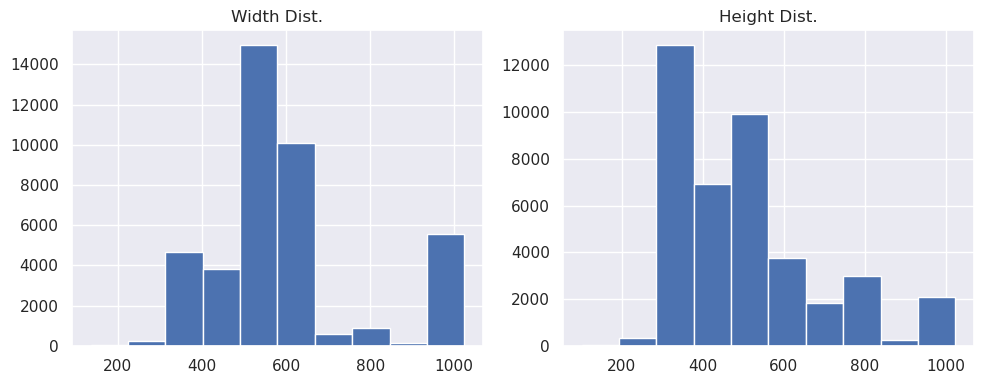

In [21]:
statement_dimension_data = f"""
SELECT
	width,
	height
FROM {database_name}.{manifest_table}
"""

dimension_data = pd.read_sql(statement_dimension_data, engine)
dimension_data.head()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(dimension_data["width"])
ax[0].set_title("Width Dist.")

ax[1].hist(dimension_data["height"])
ax[1].set_title("Height Dist.")

plt.tight_layout()
plt.show()

In [22]:
%store database_name
%store manifest_table    
%store landmarks_table 
%store s3_staging_dir

Stored 'database_name' (str)
Stored 'manifest_table' (str)
Stored 'landmarks_table' (str)
Stored 's3_staging_dir' (str)
